# Betting Against Beta — Section 6 (Cost and Persistence) and Section 7 (Recommendation)

**Data.** CRSP monthly common stocks on NYSE, AMEX and Nasdaq, 1963-01 to 2026-09, and Ken French's `Mkt-RF` and `RF`, read from `Project_Beta/data/`. We use the supplied **delisting-adjusted returns** (`ret`). Excess returns subtract `RF`; the market is `Mkt-RF`.

**Conventions.** These are the same as in `B_sections2_3.ipynb` and `sections4_5.ipynb`. A portfolio formed at month end *t* uses data through *t*, earns the return of *t+1*, and uses market cap at *t*. Means are annualized ×12 and volatilities ×√12. Sharpe ratios use excess returns, with standard error $\sqrt{(1+SR^2/24)/N}$ for *N* years. Alpha and beta come from OLS on `Mkt-RF`; alpha is annualized ×12, and every t-statistic is the plain OLS t-statistic. **Every full-sample exhibit runs from 1966-01 to 2026-09.** "Pre-2014" means 1966-01 to 2013-12 (48 years). "From 2014" means 2014-01 to 2026-09 (twelve years and nine months).

**The two books** are the default book (Section 3) and the NYSE-20th-percentile size-screened book (Section 4), rebuilt with `bab_extra.make_books`, the recipe Section 5 used. The 5.1 criteria, declared before any Section 5 or 6 result was computed, are graded in 7.1.

**Costs.** Each name traded at formation date *t* is placed in an NYSE size quintile at *t*. The breakpoints are the 20th, 40th, 60th and 80th percentiles of market cap among NYSE names with positive cap at *t*. Every name, whatever its exchange, is placed by them, and a name at a breakpoint goes to the upper quintile, as in the Section 4 screen. The month's cost is $\sum_i |w_{i,t} - w^{\text{drift}}_{i,t-1}| \times c(q_i)$, on the same signed, levered weights and drift as the 3.4 turnover. It is charged to the holding month *t+1*, so the net return is the book's excess return minus that cost. Two choices are ours:
- The first formation month (1965-12) is charged for the initial purchase (drifted weight zero). The 3.4 turnover average leaves it out.
- A name sold at *t* that has no positive cap at *t* (for example, one that delisted) takes its quintile from *t*−1, the last date it was held.

New helpers are in `bab_costs.py`. `bab_core.py` and `bab_extra.py` are unchanged.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import bab_core as bc
import bab_extra as bx
import bab_costs as bk

panel = bx.load_panel()                               # bab_core.load_panel on Project_Beta/data
mkt = panel.mkt
recipe = bx.make_books(panel)                         # {"default": (book, weights), "screened": (book, weights)}
names = {"default": "default", "screened": "screened (NYSE p20)"}
books = {names[k]: b for k, (b, _) in recipe.items()}
weights = {names[k]: w for k, (_, w) in recipe.items()}

FULL, PRE, POST = "1966-01 to 2026-09", "1966-01 to 2013-12", "2014-01 to 2026-09"
periods = {FULL: (None, None), PRE: (None, "2013-12"), POST: ("2014-01", None)}

out_dir = bx.DATA_DIR.parent / "output"
for k, b in recipe.items():
    saved = pd.read_csv(out_dir / f"book_{k}.csv", index_col="date", parse_dates=True)
    print(f"{names[k]}: {len(b[0])} holding months, {b[0].index[0]:%Y-%m} to {b[0].index[-1]:%Y-%m}; "
          f"max abs difference from output/book_{k}.csv: {(saved['book'] - b[0]['book']).abs().max():.1e}")


def show(df, pct=(), precision=3):
    display(df.style.format({c: "{:.2%}" for c in pct}, precision=precision))

default: 729 holding months, 1966-01 to 2026-09; max abs difference from output/book_default.csv: 1.5e-16
screened (NYSE p20): 729 holding months, 1966-01 to 2026-09; max abs difference from output/book_screened.csv: 1.6e-16


## Traded weight by NYSE size quintile

`bk.traded_by_quintile` rebuilds each month's trades from the signed levered weights, using the drift and rescaling of `build_book`. It checks that their total equals the 3.4 turnover in every month from the second formation date. The table reports the average traded weight per month in each quintile, as a share of capital, and each quintile's share of all trading.

In [2]:
traded, info = {}, {}
for name, b in books.items():
    traded[name], info[name] = bk.traded_by_quintile(weights[name], panel, book=b)
print("rebuilt trades match build_book turnover in every month (checked inside traded_by_quintile)")
show(pd.DataFrame(info).T, pct=["their share of all traded weight"])

rows = {}
for name, tr in traded.items():
    for per, (a, z) in [(FULL, (None, None)), (POST, ("2014-01", None))]:
        t = tr.loc[a:z]
        r = t.mean()
        rows[(name, per, "traded / month")] = r
        rows[(name, per, "share of trading")] = r / r["total"]
by_q = pd.DataFrame(rows).T.rename_axis(["construction", "period", "measure"])
by_q.columns = ["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest", "total"]
show(by_q, pct=by_q.columns)

for k, name in names.items():
    traded[name].to_csv(out_dir / f"traded_by_quintile_{k}.csv", date_format="%Y-%m-%d")

rebuilt trades match build_book turnover in every month (checked inside traded_by_quintile)


,trades taking the t-1 quintile,their share of all traded weight
default,1378.000,0.36%
screened (NYSE p20),149.000,0.09%


## 6. Cost and Persistence

### 6.1 Costs, financing and break-even

**High schedule:** one-way cost 100 / 50 / 30 / 20 / 10 bp per unit of traded weight, smallest to largest NYSE quintile. Cost per year is 12 × the mean monthly cost. The net Sharpe ratio is that of the monthly excess return minus the month's cost.

**Financing:** a 50 bp annual spread on the notional $(L_L-1)^+ + L_H$, the amount borrowed for the long leg plus the short proceeds, charged monthly as $0.005/12 \times$ notional. As 5.1 specifies, it is reported separately and is not deducted in criterion 1. The last column, net of both, is for the 7.2 discussion only.

In [3]:
cost_high = {name: bk.trading_cost(traded[name], bk.HIGH) for name in books}
fin = {name: bk.financing_drag(b) for name, b in books.items()}


def sharpe(x):
    return np.sqrt(12) * x.mean() / x.std()


rows = {}
for name, b in books.items():
    for per in [FULL, POST]:
        a, z = periods[per]
        g, c, f = b["book"].loc[a:z], cost_high[name].loc[a:z], fin[name].loc[a:z]
        notional = (b["lev_L"] - 1).clip(lower=0).loc[a:z] + b["lev_H"].loc[a:z]
        rows[(name, per)] = {
            "gross mean": 12 * g.mean(), "high-schedule cost / yr": 12 * c.mean(), "net mean": 12 * (g - c).mean(),
            "gross Sharpe": sharpe(g), "net Sharpe (high)": sharpe(g - c),
            "avg financing notional": notional.mean(), "financing drag / yr": 12 * f.mean(),
            "net Sharpe (high + financing)": sharpe(g - c - f), "months": len(g)}
costs = pd.DataFrame(rows).T.rename_axis(["construction", "period"])
costs["months"] = costs["months"].astype(int)
show(costs, pct=["gross mean", "high-schedule cost / yr", "net mean", "financing drag / yr"], precision=2)

by_q_cost = pd.DataFrame({name: 12 * traded[name][bk.QUINTILES].mean() * bk.HIGH for name in books}).T
by_q_cost.columns = ["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest"]
by_q_cost["total"] = by_q_cost.sum(axis=1)
print(f"High-schedule cost per year by NYSE size quintile, {FULL}")
show(by_q_cost, pct=by_q_cost.columns)

High-schedule cost per year by NYSE size quintile, 1966-01 to 2026-09


,Q1 smallest,Q2,Q3,Q4,Q5 largest,total
default,2.81%,0.27%,0.11%,0.06%,0.03%,3.26%
screened (NYSE p20),0.36%,0.78%,0.24%,0.13%,0.05%,1.55%


**Break-even, 1966-01 to 2026-09.** The uniform one-way cost per unit traded at which the full-sample mean net return is zero is $c^* = \bar r_{\text{book}} / \overline{\text{traded}}$. The multiple of the high schedule that does the same is $k^* = \bar r_{\text{book}} / \overline{\text{cost}}_{\text{high}}$. The high schedule's own average cost per unit traded, $\overline{\text{cost}}_{\text{high}} / \overline{\text{traded}}$, is shown beside $c^*$. Trading costs only.

In [4]:
be = pd.DataFrame({name: bk.break_even(b, traded[name], bk.HIGH) for name, b in books.items()}).T
show(be, pct=["mean gross excess (ann.)", "traded weight / month", "schedule cost per unit traded",
              "break-even uniform cost per unit traded"], precision=2)
print("in basis points per unit traded: " + "; ".join(
    f"{n}: schedule {1e4 * r['schedule cost per unit traded']:.0f} bp vs break-even "
    f"{1e4 * r['break-even uniform cost per unit traded']:.0f} bp" for n, r in be.iterrows()))

,mean gross excess (ann.),traded weight / month,schedule cost per unit traded,break-even uniform cost per unit traded,break-even multiple of schedule
default,8.75%,35.32%,0.77%,2.06%,2.68
screened (NYSE p20),5.52%,32.30%,0.40%,1.42%,3.56


in basis points per unit traded: default: schedule 77 bp vs break-even 206 bp; screened (NYSE p20): schedule 40 bp vs break-even 142 bp


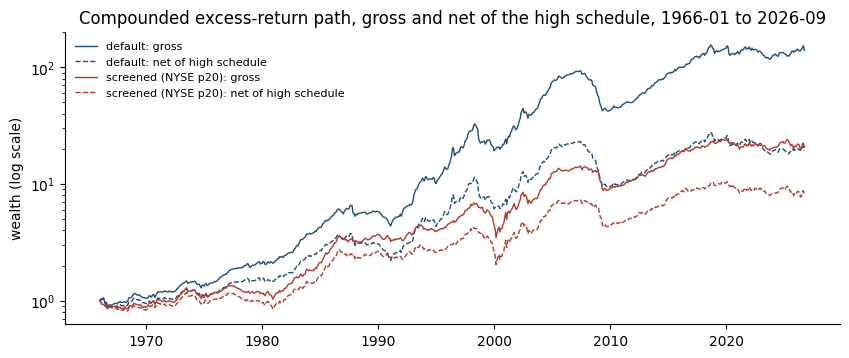

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for (name, b), color in zip(books.items(), ["#1f4e79", "#b03a2e"]):
    ax.plot(bx.wealth_path(b["book"]), color=color, lw=1, label=f"{name}: gross")
    ax.plot(bx.wealth_path(b["book"] - cost_high[name]), color=color, lw=1, ls="--", label=f"{name}: net of high schedule")
ax.set_yscale("log")
ax.set(title=f"Compounded excess-return path, gross and net of the high schedule, {FULL}", ylabel="wealth (log scale)")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**6.1.** Under the high schedule, trading costs take 3.26% a year from the default book and 1.55% from the screened book over 1966-01 to 2026-09 (3.01% and 1.40% from 2014). The full-sample Sharpe ratio falls from 0.81 to 0.51 for the default and from 0.54 to 0.39 for the screened book. From 2014 both fall to 0.25.

The default pays twice as much for a reason the composition in 3.4 already pointed to. Two-thirds of its trading (66%; 60% from 2014) is in the smallest NYSE quintile, at 100 bp, so its average cost is 77 bp per unit traded. The screened book's average is 40 bp, with 40% of its trading in the second quintile at 50 bp. It still does 9% of its trading in the smallest quintile, 0.36% a year of its 1.55%. These are sales of names that fell below the NYSE 20th percentile since the last formation date. A size screen forces the book to trade at the worst cost precisely when a name leaves it.

The 50 bp financing spread adds 0.60% a year for the default (average notional 1.20) and 0.52% for the screened book (1.03). Net of both, the Sharpe ratios are 0.45 and 0.34.

**Against the break-even, the schedule is well inside it.** The default would need a uniform cost of 206 bp per unit traded, or 2.68 times the high schedule, before its full-sample mean net return reached zero. The screened book would need 142 bp, or 3.56 times. Neither book is close to losing money after costs. The question costs raise is whether what is left is enough, and that is what criterion 1 tests. For the default, the margin is in the quintile where the illustrative 100 bp is least reliable, since 21% of its long leg and 29% of its short leg are priced under $5. Borrow fees on the short leg are not in either number.

### 6.2 Persistence: before and from 2014

For each book over 1966-01 to 2013-12 and 2014-01 to 2026-09: the gross Sharpe ratio with its standard error, alpha with its t-statistic, realized beta, and the net Sharpe ratio under the high schedule. The full sample is shown for reference.

Three diagnostics follow, all from the standard errors. Because the two windows do not overlap, their Sharpe estimates are treated as independent.
- $SR/se$ for each window: how far each Sharpe ratio is from zero.
- $(SR_{\text{post}} - SR_{\text{pre}})/\sqrt{se_{\text{pre}}^2 + se_{\text{post}}^2}$: whether the later window differs from the earlier one.
- The mean split into alpha + beta × the window's market premium, which is exact for OLS. It shows how much of each window's return is market exposure.

In [6]:
rows = {}
for name, b in books.items():
    for per, (a, z) in periods.items():
        g = b["book"].loc[a:z]
        p = bc.performance(g, mkt)
        prem = 12 * mkt.reindex(g.index).mean()
        rows[(name, per)] = {"sharpe": p["sharpe"], "sharpe_se": p["sharpe_se"], "SR / se": p["sharpe"] / p["sharpe_se"],
                             "alpha": p["alpha"], "t_alpha": p["t_alpha"], "beta": p["beta"],
                             "net Sharpe (high)": sharpe(g - cost_high[name].loc[a:z]),
                             "mean": p["mean"], "beta x premium": p["beta"] * prem, "market premium": prem,
                             "months": int(p["months"])}
persist = pd.DataFrame(rows).T.rename_axis(["construction", "period"])
show(persist, pct=["alpha", "mean", "beta x premium", "market premium"], precision=2)

diff = {}
for name in books:
    pre, post = persist.loc[(name, PRE)], persist.loc[(name, POST)]
    se = np.hypot(pre["sharpe_se"], post["sharpe_se"])
    diff[name] = {"SR post - SR pre": post["sharpe"] - pre["sharpe"], "se of difference": se,
                  "z": (post["sharpe"] - pre["sharpe"]) / se,
                  "years for post-2014 SR to sit 2 se from 0": 4 * (1 + post["sharpe"]**2 / 24) / post["sharpe"]**2}
show(pd.DataFrame(diff).T, precision=2)

,SR post - SR pre,se of difference,z,years for post-2014 SR to sit 2 se from 0
default,-0.30,0.32,-0.94,12.80
screened (NYSE p20),-0.16,0.32,-0.52,24.69


**6.2.** **Before 2014 the evidence is strong.** Over 48 years the default book's Sharpe ratio is 0.86 (standard error 0.15), with alpha 8.65% (t = 5.49). The screened book's is 0.57 (0.15), with alpha 5.99% (t = 3.90). Net of the high schedule they are 0.57 and 0.42.

**From 2014 the Sharpe ratios are 0.56 and 0.40, but with standard errors of 0.28.** Twelve years and nine months is a quarter of the earlier window, so the standard error is about twice as large. Even the default's gross Sharpe ratio sits only 2.0 standard errors from zero, and much of it is not the low-beta premium. Its 5.38% mean splits into 1.85% alpha (t = 0.76) and 3.52% from its realized beta of 0.30 times a market premium of 11.87%, the highest of any window here. The screened book has almost no beta (0.06), so its 3.70% is mostly alpha (3.02%), but with t = 1.15. Net of costs, both books' post-2014 Sharpe ratios are 0.25, under one standard error from zero.

**What the period since 2014 can establish is limited.** It shows the trade did not lose money gross. It cannot establish that the premium persisted: neither alpha is distinguishable from zero. It also cannot establish that the premium declined. The fall from the pre-2014 Sharpe ratio is 0.30 (default) and 0.16 (screened), only −0.94 and −0.52 standard errors of the difference. The two windows are statistically compatible. A Sharpe ratio of 0.56 would need about 13 years to sit two standard errors from zero, and 0.40 about 25 years, so this window could not have settled the question either way. The case for the strategy therefore rests on the pre-2014 window. The recent window is consistent both with a smaller premium continuing and with no premium at all.

## 7. Recommendation

### 7.1 The 5.1 criteria

As declared in 5.1, before any Section 5 or 6 result was computed, and applied to each construction separately:
1. **Full sample, after costs:** Sharpe ratio over 1966-01 to 2026-09, net of the 6.1 high trading-cost schedule (financing not deducted), **at least 0.40**.
2. **Down-market beta:** beta over the months of 1966-01 to 2026-09 with Mkt-RF < 0 (OLS with intercept, as in 5.4; point estimate), **at most 0.25**.

In [7]:
grade = {}
for name, b in books.items():
    net_sr = costs.loc[(name, FULL), "net Sharpe (high)"]
    down = bx.up_down_beta(b["book"], mkt).loc["down (Mkt-RF < 0)"]
    grade[(name, "1. full-sample net Sharpe (high) >= 0.40")] = {"value": net_sr, "threshold": 0.40, "pass": net_sr >= 0.40}
    grade[(name, "2. down-market beta <= 0.25")] = {"value": down["beta"], "threshold": 0.25, "pass": down["beta"] <= 0.25,
                                                     "t": down["t_beta"], "months": int(down["months"])}
grade = pd.DataFrame(grade).T.rename_axis(["construction", "criterion"])
show(grade, precision=3)
for name in books:
    print(f"{name}: {'PASSES' if grade.loc[name, 'pass'].all() else 'FAILS'} the 5.1 criteria "
          f"({int(grade.loc[name, 'pass'].sum())} of 2)")

default: FAILS the 5.1 criteria (1 of 2)
screened (NYSE p20): FAILS the 5.1 criteria (1 of 2)


**7.1.** **Both constructions fail, each on a different criterion.**
- *Default book:* criterion 1 passes (net Sharpe 0.506 ≥ 0.40), but criterion 2 fails. Its down-market beta of 0.49 (t = 8.85, 296 months) is about twice the 0.25 limit.
- *Screened book:* criterion 2 passes (0.13), but criterion 1 fails. Its net Sharpe of 0.385 is 0.015 short of 0.40, about a tenth of the 0.13 standard error. That is not a meaningful statistical difference. But the threshold was fixed before the result was seen, so it is reported as a fail and the criteria are not revised.

The overall decisions agree (neither passes), but the failures are of different kinds. If one construction had to be run, we would prefer the screened book. Its failure is a narrow miss on the size of the return. The default's is structural: it loses about half of each market decline, the exposure behind its −54.9% drawdown in 2007–09. Section 4 traced that exposure to measurement error in small-stock betas, which over-levers the long leg. The default's higher net Sharpe also comes from the micro-caps where the cost assumption is weakest.

### 7.2 Should an allocator invest?

The numbers the memo relies on, from 3.1, 3.4, 4.2 and 6.1 (holding months 1966-01 to 2026-09 unless marked).

In [8]:
memo = {}
for name, b in books.items():
    memo[name] = {
        "names per leg (median)": b["n_L"].median(), "long leverage (median)": b["lev_L"].median(),
        "long leverage (max)": b["lev_L"].max(), "short leverage (median)": b["lev_H"].median(),
        "cash (median)": b["cash"].median(), "one-way turnover / month": b["turnover"].mean(),
        "long: price < $5": b["penny_L"].mean(), "short: price < $5": b["penny_H"].mean(),
        "long: below NYSE p20": b["small_L"].mean(), "short: below NYSE p20": b["small_H"].mean(),
        "trading in Q1 (smallest), from 2014": by_q.loc[(name, POST, "share of trading"), "Q1 smallest"],
        "net Sharpe (high), from 2014": costs.loc[(name, POST), "net Sharpe (high)"],
        "alpha from 2014": persist.loc[(name, POST), "alpha"], "t_alpha from 2014": persist.loc[(name, POST), "t_alpha"],
    }
memo = pd.DataFrame(memo)
display(memo.style.format("{:.2f}").format("{:.1%}", subset=pd.IndexSlice[[
    "one-way turnover / month", "long: price < $5", "short: price < $5", "long: below NYSE p20",
    "short: below NYSE p20", "trading in Q1 (smallest), from 2014", "alpha from 2014"], :]))
m_full, m_post = mkt.loc["1966-01":"2026-09"], mkt.loc["2014-01":"2026-09"]
print(f"Mkt-RF Sharpe ratio: {sharpe(m_full):.2f} ({FULL}), {sharpe(m_post):.2f} ({POST})")

,default,screened (NYSE p20)
names per leg (median),1880.00,824.00
long leverage (median),1.45,1.30
long leverage (max),3.15,1.99
short leverage (median),0.64,0.66
cash (median),0.19,0.35
one-way turnover / month,35.1%,32.1%
long: price < $5,21.2%,0.7%
short: price < $5,28.9%,3.1%
long: below NYSE p20,59.1%,0.0%
short: below NYSE p20,56.1%,0.0%


Mkt-RF Sharpe ratio: 0.45 (1966-01 to 2026-09), 0.79 (2014-01 to 2026-09)


**7.2. Recommendation: do not invest.** Our candidate was the screened book. It holds US common stocks at or above the NYSE 20th percentile of market cap at each month end, about 824 names per leg. Stocks are ranked on 0.6·β̂₆₀ + 0.4, rank-weighted, and each leg is levered to an ex-ante beta of one: long leverage median 1.30 (maximum 1.99), short 0.66, cash 0.35. The default book is not a candidate. It is unhedged on the way down (down-market beta 0.49), and over half of each leg sits below the NYSE 20th percentile, with 21% and 29% under $5.

Capacity is not what stops the screened book. Every name clears the size cut, only 3% of the short leg is under $5, and turnover is 32% of capital a month. **The problem is that what can be captured at scale does not earn enough.** Its net Sharpe ratio is 0.39 over 1966–2026, below our 0.40 hurdle and the market's 0.45. It is 0.34 after financing, and 0.25 since 2014, when the market's was 0.79. Its alpha since 2014 is 3.0% (t = 1.15), so the persuasive evidence is all pre-2014 (6.2). The zero-beta label also hides a risk: in 5.2 it lost 49.6% (gross) from 1998-03 to 2000-02 while the market rose, and was under water for 47 months.

Unresolved: short borrow fees (not modelled), real trading costs rather than the illustrative schedule, whether the post-2014 weakening is a decline or noise (6.2), and whether the premium is mispricing or compensation for an omitted risk (2.4).

### 7.3 What would reverse the recommendation

The recommendation in 7.2 is not to invest. It rests on the screened book's net Sharpe ratio falling short of the 0.40 hurdle. The result that would reverse it is the book clearing that hurdle out of sample, by enough that luck is an unlikely explanation.

With a true annualized Sharpe ratio $S$, the Sharpe ratio realized over the next $N$ years has standard error $se(N) = \sqrt{(1+S^2/24)/N}$. We choose *N* as the shortest horizon at which a realized Sharpe ratio equal to the hurdle, $S = 0.40$, would sit 1.645 standard errors above zero, the one-sided 5% level:

$$0.40 = 1.645\,\sqrt{\frac{1 + 0.40^2/24}{N}} \quad\Longrightarrow\quad N = \frac{1.645^2\,(1 + 0.40^2/24)}{0.40^2}.$$

The table shows the arithmetic, and how far 0.40 would sit from zero over shorter horizons, including the 12.75 years since 2014.

In [9]:
z, S = 1.645, 0.40
N = z**2 * (1 + S**2 / 24) / S**2
print(f"N = {z}^2 x (1 + {S}^2/24) / {S}^2 = {z**2:.4f} x {1 + S**2 / 24:.5f} / {S**2:.2f} = {N:.2f} years")
for n in [5, 10, 12.75, round(N), 25]:
    se = np.sqrt((1 + S**2 / 24) / n)
    print(f"  N = {n:>5}: se = sqrt({1 + S**2 / 24:.5f} / {n}) = {se:.3f};  a realized 0.40 is {S / se:.2f} se above zero")

N = 1.645^2 x (1 + 0.4^2/24) / 0.4^2 = 2.7060 x 1.00667 / 0.16 = 17.03 years
  N =     5: se = sqrt(1.00667 / 5) = 0.449;  a realized 0.40 is 0.89 se above zero
  N =    10: se = sqrt(1.00667 / 10) = 0.317;  a realized 0.40 is 1.26 se above zero
  N = 12.75: se = sqrt(1.00667 / 12.75) = 0.281;  a realized 0.40 is 1.42 se above zero
  N =    17: se = sqrt(1.00667 / 17) = 0.243;  a realized 0.40 is 1.64 se above zero
  N =    25: se = sqrt(1.00667 / 25) = 0.201;  a realized 0.40 is 1.99 se above zero


**7.3.** We would reverse the recommendation if the screened book, run exactly as specified from 2026-10, realizes a **net Sharpe ratio of at least 0.40 under the high schedule over the next 17 years**, to 2043-09. The horizon comes from the formula: N = 1.645² × (1 + 0.40²/24) / 0.40² = 2.7060 × 1.00667 / 0.16 = 17.0 years. At that horizon se = √(1.00667/17) = 0.243, and 1.645 × 0.243 = 0.40, so a realized 0.40 would be significant at the one-sided 5% level. Over any shorter horizon the same result could easily be luck: over ten years a 0.40 would be only 1.26 standard errors above zero, and over the 12.75 years since 2014 only 1.42. The length of the horizon is itself part of the answer. A Sharpe ratio near our hurdle takes almost two decades of new data to confirm.

## Citations

AI Citations: Claude Opus 5.5 (Anthropic) was used to assist with the code (`bab_costs.py` and this notebook) and with the analysis and writing for Sections 6 and 7. The 5.1 criteria and thresholds graded in 7.1 were chosen by the group before any Section 5 or 6 result was computed. Every number in the text comes from the executed cells above.